# §8 Fairness and the 3 × 3 Label Matrix (Stage S8)

§5 showed that the label and one feature are measured unevenly across groups: self-report misses the 152 people
whose diabetes is undiagnosed, and these people are more often uninsured or without a usual place of care, while BMI
under-reads adiposity in Asian adults. This section checks whether those measurement biases **carry over into the
model**. Three parts follow:

1. **Group audit** – error rates of arm S by race, insurance, access to care, income and sex at one fixed threshold,
   with bootstrap intervals, small-cell suppression and a permutation baseline.
2. **3 × 3 label matrix** (pre-registered H3) – the same pipeline trained on three labels and scored on three kinds
   of diabetes, plus an audit arm that shows how the access-to-care imprint differs between labels.
3. **Mitigation** – reweighing (race, insurance, access), the WHtR measurement fix (P14-b), the fairness–performance
   trade-off and within-group calibration.

All results use the out-of-fold (OOF) predictions of the **training part** and the stored folds of §7. The 20 %
hold-out is not read; its single use belongs to S9 after `exp-freeze`. Race, insurance and access never enter the
prediction model (S1 availability rule): they are audit variables only.

Contents: 0 setup · 1 audit groups · 2 group metrics · 3 gaps and permutation baseline · 4 E-SCREEN · 5 Tier 2 ·
6 3 × 3 label matrix · 7 access-proxy audit · 8 reweighing · 9 WHtR fix · 10 group-specific thresholds ·
11 trade-off · 12 within-group calibration · 13 verdicts · 14 register and storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as SV, fairness as F

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
OUT = C.RESULTS_DIR / "S8"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
N_PERM_GROUP = 200          # group-label permutations (process doc S8 step 2)
SPEC = C.SPEC_FIXED
GAP, GAP_SUB = C.SESOI["group_tpr_gap"], C.SESOI["group_tpr_gap_substantive"]
T_START = time.time()
S8 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm_group": N_PERM_GROUP,
      "spec": SPEC}
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, {N_PERM_GROUP} group permutations, {N_JOBS} workers")

mode FAST: 5x2 CV, B = 100, 200 group permutations, 12 workers


## 0 Setup
**Why.** S8 must evaluate exactly the predictions that §7 judged, on the same rows and folds. The cohort is rebuilt, the
stored hold-out split is re-verified (not evaluated), the stored folds are reloaded with their hash, and the stored OOF
file is checked against those folds. One fold of arm S is refitted to prove that a refit reproduces the stored
predictions, so that the new arms below (other labels, reweighing) are paired with S on identical terms.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X1 = P.raw_feature_frame(raw_tr, 1)
y = cl["L_comb"].to_numpy().astype(int)
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold, n_train_fold = n / C.CV_SPLITS, n - n / C.CV_SPLITS
grp = F.audit_groups(cl)
S7m = R.load_section("S7")
C0 = float(S7m["C0"]["C0"])
assert folds.hash[:16] == S7m["splits"]["folds_hash"][:16] or C.NB_MODE == "FAST"

oof_all = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet")
oof_all = oof_all[oof_all["repeat"] < C.CV_REPEATS]          # FAST folds = first 2 repeats of the FINAL folds
assert not set(oof_all["SEQN"]) & set(clean["SEQN"].iloc[te]) and set(oof_all["SEQN"]) <= set(cl["SEQN"])   # no hold-out row
assert (oof_all.drop_duplicates("row").set_index("row")["SEQN"].sort_index().to_numpy() == cl["SEQN"].to_numpy()).all()
OOF = {}
for (a, t, m), g in oof_all.groupby(["arm", "tier", "model"], observed=True):
    OOF[(a, int(t), m)] = g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)
# every stored (repeat, fold) test set equals the stored fold file
s_oof = OOF[("S", 1, "lr")]
for i, (_, te_i) in enumerate(folds):
    r_, f_ = i // folds.n_splits, i % folds.n_splits
    assert np.array_equal(np.sort(s_oof.query("repeat == @r_ and fold == @f_")["row"].to_numpy()), te_i)
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}            # repeat-averaged OOF probability per row

cfgS = P.ARMS["S"]
fpS = P.fit_params(cfgS, raw_tr)
w_svy = P.survey_weights(raw_tr)
tr0, te0 = folds[0]
m0 = P.build_pipeline(cfgS, 1, C_=C0).fit(X1.iloc[tr0], y[tr0], model__sample_weight=w_svy[tr0])
refit = m0.predict_proba(X1.iloc[te0])[:, 1]
stored = s_oof.query("repeat == 0 and fold == 0").set_index("row").loc[te0, "prob"].to_numpy()
max_dev = float(np.abs(refit - stored).max())
assert max_dev < 1e-5, max_dev
assert np.array_equal(P.training_label(raw_tr, cfgS), y)        # arm S trains on the frozen L_comb
print(f"training part {n:,} rows, {y.sum()} L_comb positives; E-SCREEN {esc.sum():,} rows, {y_esc[esc].sum()} positives")
print(f"folds {folds.n_splits}x{folds.n_repeats}, hash {folds.hash[:16]}...; C0 = {C0}; OOF runs loaded: {len(OOF)}")
print(f"refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = {max_dev:.2e} (float32 storage)")
S8["setup"] = dict(n_train=n, n_pos=int(y.sum()), n_escreen=int(esc.sum()), n_pos_escreen=int(y_esc[esc].sum()),
                   folds_hash=folds.hash, C0=C0, refit_max_abs_diff=max_dev)

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives
folds 5x2, hash eb0f2b5f07f6613b...; C0 = 0.1; OOF runs loaded: 46
refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = 2.97e-08 (float32 storage)


**So what.** The stored predictions belong to the stored folds, and refitting arm S reproduces them to float32
precision. Every new arm in this section is therefore a paired comparison with the S predictions that §7 evaluated.
The training part holds 4,584 adults; the E-SCREEN subset has only about 127 positives.

## 1 Audit groups
**Why.** The audit must be planned around cell sizes. With no race or income oversampling in this cycle, several groups
have only a few dozen cases. Five attributes are audited: race (NH Asian separate and always exploratory),
insurance (HIQ011), **low access** (uninsured *or* no usual place of care, HUQ030 – the two access measures §5 linked
to being undiagnosed), income band (PIR < 1.3 / 1.3–3.49 / ≥ 3.5 / missing) and sex. The reference level is the
largest or most advantaged group. Small-cell rule (NCHS presentation standard): a group with n < 30 or fewer than 30
positives (the TPR denominator) is still shown, but no verdict is drawn on its gap.

**Ecological-fallacy caveat.** Every number below describes a *group* of people scored by the model. A lower TPR for a
group says that the model misses a larger share of that group's cases; it does not say that any individual in it
has a different risk, nor that group membership causes the difference. Group membership is also never used to
score an individual.

In [3]:
def pop_of(name):
    """(label vector, evaluation mask) of an evaluation population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    raise ValueError(name)

size_rows = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy()
        size_rows.append({"attribute": attr, "group": lv, "ref": lv == F.REFERENCE[attr], "n": int(m.sum()),
                          "pos_eall": int(y[m].sum()), "n_escreen": int((m & esc).sum()), "pos_escreen": int(y_esc[m & esc].sum()),
                          "status_eall": F.cell_status(int(m.sum()), int(y[m].sum())),
                          "status_escreen": F.cell_status(int((m & esc).sum()), int(y_esc[m & esc].sum()))})
    size_rows.append({"attribute": attr, "group": "(unknown)", "n": int(grp[attr].isna().sum())})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(OUT / "group_sizes.csv", index=False)
print(sizes.to_string(index=False))
n_supp = {p: int((sizes[f"status_{p}"] == "suppress").sum()) for p in ("eall", "escreen")}
print(f"\nsuppressed groups (n < 30 or positives < 30): E-ALL {n_supp['eall']}, E-SCREEN {n_supp['escreen']} "
      f"of {int(sizes['status_eall'].notna().sum())}")
S8["group_sizes"] = sizes.to_dict("records")
S8["n_suppressed"] = n_supp

 attribute            group   ref    n  pos_eall  n_escreen  pos_escreen status_eall status_escreen
      race         NH White  True 2727     398.0     2392.0         63.0     present        present
      race         NH Black False  540     131.0      433.0         24.0     present       suppress
      race         NH Asian False  252      40.0      223.0         11.0     present       suppress
      race Mexican American False  309      69.0      256.0         16.0     present       suppress
      race   Other Hispanic False  465      82.0      394.0         11.0     present       suppress
      race      Other/Multi False  291      57.0      236.0          2.0     present       suppress
      race        (unknown)   NaN    0       NaN        NaN          NaN         NaN            NaN
 insurance          insured  True 4186     725.0     3571.0        110.0     present        present
 insurance        uninsured False  390      51.0      356.0         17.0     present       suppress


**So what.** On E-ALL every group except one passes the 30-positive rule; NH Asian adults pass with only 40 positives
and stay exploratory. On E-SCREEN almost every group falls below 30 positives, so E-SCREEN gaps are reported as numbers
only: the screening population is too small in this cycle for any group-fairness verdict except the largest groups.
That is itself a governance finding: a fairness audit of the screening use case needs more data than NHANES 2021–23
provides.

## 2 Group metrics at the fixed threshold
**Why.** Equal opportunity (Hardt et al. 2016) asks whether people *with* diabetes are found at the same rate in each
group. One threshold is fixed for everybody: the score that gives specificity 0.80 on all negatives of the population
(no group-specific thresholds, see section 10). For each group the table reports TPR (sensitivity), FPR, selection
rate, PPV, the within-group AUC and the observed-to-expected ratio (O:E = cases / sum of predicted probabilities).
Intervals come from a stratified bootstrap (rows resampled within group × label, B = `config.N_BOOT`) in which the
threshold is **re-estimated in every replicate**, so the threshold's own uncertainty is included. Arm S is
class-weighted (P11), so its probabilities are inflated by design and its O:E is far below 1 everywhere; only
differences in O:E between groups are informative for S (absolute calibration is examined in section 12). Because the
bootstrap is label-stratified, each group's prevalence is held at its observed value: intervals for TPR and FPR are
the natural conditional ones, those for selection rate and PPV are conditional on the observed prevalence.

In [4]:
AUD = {}   # (attr, pop, tier, arms) -> (point, boot, codes, mask)

def audit(attr, pop="E-ALL", tier=1, arms=("S",), weights="simple", preds=None):
    """Run the bootstrap engine for one attribute / population / tier and a tuple of arms (paired)."""
    key = (attr, pop, tier, tuple(arms), weights)
    if key in AUD and preds is None:
        return AUD[key]
    yy, m = pop_of(pop)
    lv = F.LEVELS[attr]
    codes = F.encode(grp[attr], lv)[m]
    Pm = np.vstack([(PM[(a, tier, "lr")] if preds is None or a not in preds else preds[a])[m] for a in arms])
    point = F.boot_engine(yy[m], Pm, codes, len(lv))
    seed = ek.derive_seed(C.SEED_MASTER, "S8", attr, pop, tier, weights)
    if weights == "simple":          # label-stratified: group size and group positives fixed (TPR, FPR, EOD)
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", yy[m].astype(str))), C.N_BOOT, seed)
    elif weights == "group":         # group-stratified only: observed cases vary (O:E, calibration)
        W = F.stratified_counts(codes.astype(str), C.N_BOOT, seed)
    else:
        W = F.psu_counts(cl.loc[m, [C.STRATA, C.PSU]].reset_index(drop=True), C.N_BOOT, seed)
    boot = F.boot_engine(yy[m], Pm, codes, len(lv), W)
    out = (point, boot, codes, m)
    if preds is None:
        AUD[key] = out
    return out

def tables(pop="E-ALL", tier=1, arm="S"):
    gt, et = [], []
    for attr in F.ATTRIBUTES:
        point, boot, _, _ = audit(attr, pop, tier, (arm,))
        g = F.group_table(point, boot, F.LEVELS[attr], attribute=attr)
        e = F.eod_table(point, boot, F.LEVELS[attr], F.REFERENCE[attr], attribute=attr)
        g.insert(0, "pop", pop); g.insert(1, "tier", tier)
        e.insert(0, "pop", pop); e.insert(1, "tier", tier)
        gt.append(g); et.append(e)
    return pd.concat(gt, ignore_index=True), pd.concat(et, ignore_index=True)

t0 = time.time()
GT1, ET1 = tables("E-ALL", 1)
thr_eall = float(audit("race")[0]["thr"][0, 0])
rec_check, thr_check = ek.recall_at_specificity(y, PM[("S", 1, "lr")])
assert abs(audit("race")[0]["tpr"][0, 0].dot(audit("race")[0]["n_pos"][0, 0]) / y.sum() - rec_check) < 1e-12
show = ["attribute", "group", "n", "n_pos", "tpr", "tpr_lo", "tpr_hi", "fpr", "sel", "ppv", "auc", "auc_lo", "auc_hi", "oe", "status", "flags"]
print(f"E-ALL, Tier 1, arm S: threshold {thr_eall:.4f} (specificity 0.80 on {int((y == 0).sum())} negatives); "
      f"overall TPR {rec_check:.3f}; {time.time() - t0:.1f} s")
print(GT1[show].round(3).to_string(index=False))

E-ALL, Tier 1, arm S: threshold 0.6389 (specificity 0.80 on 3807 negatives); overall TPR 0.663; 0.3 s
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe  status       flags
      race         NH White 2727    398 0.693   0.644   0.744 0.210 0.281 0.360 0.844   0.829   0.855 0.356 present            
      race         NH Black  540    131 0.618   0.538   0.691 0.227 0.322 0.466 0.782   0.745   0.820 0.543 present            
      race         NH Asian  252     40 0.475   0.362   0.650 0.123 0.179 0.422 0.856   0.813   0.904 0.498 present exploratory
      race Mexican American  309     69 0.609   0.514   0.732 0.146 0.249 0.545 0.840   0.787   0.889 0.570 present            
      race   Other Hispanic  465     82 0.744   0.664   0.836 0.175 0.275 0.477 0.869   0.833   0.905 0.437 present            
      race      Other/Multi  291     57 0.632   0.500   0.746 0.214 0.296 0.419 0.834   0.756   0.875 0.462 present            
 i

**So what.** At one shared threshold the model finds about two thirds of all cases, but not evenly. The lowest
TPRs belong to NH Asian adults, the low-access group and the uninsured; the highest to the lowest income band. Low
TPR comes with low FPR and low selection rate in the same groups (NH Asian, low access, uninsured): the whole score
distribution of these groups sits lower, so the single threshold selects fewer of them, cases and non-cases alike.
Within-group AUCs overlap widely (about 0.78–0.87), so the *ranking* inside each group is similar; the gaps arise
from where each group's scores lie relative to the shared threshold. Whether they exceed sampling noise is tested
next.

## 3 Gaps and permutation baseline
**Why.** A gap is only interesting if it is larger than what random group labels would produce. Two checks are
combined: (i) the equal-opportunity difference EOD = TPR_group − TPR_reference with its bootstrap CI, flagged at
|EOD| ≥ 0.05 (SESOI) and called **substantive** only if |EOD| ≥ 0.10 *and* its CI excludes 0; (ii) a group-label
permutation null: group labels are shuffled 200 times (sizes kept, threshold fixed) and the observed max |EOD| over
the reportable groups is compared with the null distribution of that maximum. The maximum is the right statistic
because with six race groups the largest of five gaps is expected to look sizeable even by chance.

In [5]:
def permutation_block(pop="E-ALL", tier=1, arm="S", preds=None):
    rows, nulls = [], {}
    yy, m = pop_of(pop)
    for attr in F.ATTRIBUTES:
        point, boot, codes, mm = audit(attr, pop, tier, (arm,), preds=preds)
        lv = F.LEVELS[attr]
        ref = lv.index(F.REFERENCE[attr])
        ok = [g for g in range(len(lv)) if F.cell_status(int(point["n"][0, 0, g]), int(point["n_pos"][0, 0, g])) == "present"]
        p_ = (PM[(arm, tier, "lr")] if preds is None else preds[arm])[mm]
        thr = np.nextafter(point["thr"][0, 0], np.inf)        # engine: positive if p > v  <=>  p >= nextafter(v)
        if ref not in ok or len(ok) < 2:
            rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - (ref in ok),
                         "observed_max_eod": np.nan, "null_q95": np.nan, "p_value": np.nan, "note": "reference or all groups suppressed"})
            continue
        res = F.eod_permutation(yy[mm], p_, codes, len(lv), ref, thr, eligible=ok, n_perm=N_PERM_GROUP,
                                seed=ek.derive_seed(C.SEED_MASTER, "S8", "perm", attr, pop, tier))
        tp = point["tpr"][0, 0]
        assert abs(res["observed"] - max(abs(tp[g] - tp[ref]) for g in ok if g != ref)) < 1e-12
        nulls[attr] = res["null"]
        rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - 1,
                     "observed_max_eod": res["observed"], "null_mean": res["null_mean"], "null_q95": res["null_q95"],
                     "p_value": res["p_value"], "note": ""})
    return pd.DataFrame(rows), nulls

PERM1, NULL1 = permutation_block("E-ALL", 1)
print("Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):")
print(ET1[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "fpr_diff", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print("\nPermutation null of max |EOD| (reportable groups only):")
print(PERM1.round(3).to_string(index=False))
sub1 = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
print(f"\nsubstantive gaps (|EOD| >= {GAP_SUB}, CI excludes 0, reportable): {len(sub1)} -> "
      f"{sub1[['attribute', 'group', 'eod']].round(3).to_dict('records')}")

Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):
 attribute            group          ref    eod  eod_lo  eod_hi  fpr_diff  flag_0.05  substantive verdict_status
      race         NH Black     NH White -0.075  -0.171   0.013     0.017       True        False     reportable
      race         NH Asian     NH White -0.218  -0.352  -0.080    -0.088       True         True     reportable
      race Mexican American     NH White -0.085  -0.193   0.037    -0.065       True        False     reportable
      race   Other Hispanic     NH White  0.050  -0.043   0.155    -0.035       True        False     reportable
      race      Other/Multi     NH White -0.062  -0.190   0.068     0.003       True        False     reportable
 insurance        uninsured      insured -0.058  -0.170   0.064    -0.081       True        False     reportable
low_access       low access usual access -0.084  -0.199   0.031    -0.121       True        False     reportable
    income     PIR 1.3

**So what.** Two attributes carry gaps that survive both checks: **race**, driven by NH Asian adults (exploratory,
40 positives), and **income**, where the *lower* income bands are found *more* often than the highest band. Their
largest gaps exceed the 95th percentile of the permutation null. Insurance and sex show nothing beyond chance on
E-ALL; the low-access gap sits at the edge of the null. The next table asks *why* these groups differ, because race,
insurance and access are not model inputs: a gap must travel through correlated features.

### Where the gaps come from
**Why.** On E-ALL, 84 % of positives already know their diagnosis and carry care traces (told hypertension or high
cholesterol, BPQ020/BPQ080), which raise the score. If a group's cases are less often diagnosed, or are younger or
leaner, the shared threshold will miss more of them. The table describes the positives of each group: share
diagnosed, mean age, mean BMI, and the TPR separately for diagnosed and undiagnosed cases.

In [6]:
pS = PM[("S", 1, "lr")]
hitS = pS >= thr_check
dec = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy() & (y == 1)
        dx = m & (cl["L_self"].to_numpy() == 1)
        ud = m & (cl["L_self"].to_numpy() == 0)
        dec.append({"attribute": attr, "group": lv, "n_pos": int(m.sum()), "share_diagnosed": dx.sum() / m.sum(),
                    "mean_age": cl.loc[m, "RIDAGEYR"].mean(), "mean_bmi": cl.loc[m, "BMXBMI"].mean(),
                    "care_trace": (cl.loc[m, "BPQ020"].eq(1) | cl.loc[m, "BPQ080"].eq(1)).mean(),
                    "tpr": hitS[m].mean(), "tpr_diagnosed": hitS[dx].mean(), "tpr_undiagnosed": hitS[ud].mean() if ud.sum() else np.nan})
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT / "gap_decomposition.csv", index=False)
print(DEC.round(3).to_string(index=False))
r_dx = float(np.corrcoef(DEC["share_diagnosed"], DEC["tpr"])[0, 1])
r_age = float(np.corrcoef(DEC["mean_age"], DEC["tpr"])[0, 1])
r_care = float(np.corrcoef(DEC["care_trace"], DEC["tpr"])[0, 1])
tpr_dx_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 1)].mean()
tpr_ud_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 0)].mean()
print(f"\nall positives: TPR diagnosed {tpr_dx_all:.3f} vs undiagnosed {tpr_ud_all:.3f}")
print(f"across the 16 groups, correlation of TPR with share diagnosed {r_dx:.2f}, with care-trace share {r_care:.2f}, "
      f"with mean age {r_age:.2f}")
S8["gap_decomposition"] = dict(table=DEC.round(4).to_dict("records"), tpr_diagnosed=tpr_dx_all, tpr_undiagnosed=tpr_ud_all,
                               r_tpr_share_diagnosed=r_dx, r_tpr_care_trace=r_care, r_tpr_mean_age=r_age)

 attribute            group  n_pos  share_diagnosed  mean_age  mean_bmi  care_trace   tpr  tpr_diagnosed  tpr_undiagnosed
      race         NH White    398            0.842    64.455    34.031       0.897 0.693          0.701            0.651
      race         NH Black    131            0.817    58.405    34.682       0.802 0.618          0.692            0.292
      race         NH Asian     40            0.725    64.550    26.441       0.800 0.475          0.552            0.273
      race Mexican American     69            0.768    59.087    32.419       0.754 0.609          0.679            0.375
      race   Other Hispanic     82            0.866    62.293    31.742       0.927 0.744          0.775            0.545
      race      Other/Multi     57            0.965    62.649    33.933       0.877 0.632          0.636            0.500
 insurance          insured    725            0.848    63.301    33.318       0.877 0.666          0.693            0.518
 insurance        uninsu

**So what.** Three different routes produce the gaps:

* **Diagnosis and care traces (label route).** The model finds diagnosed cases far more often than undiagnosed ones
  (TPRs printed above), and a group's TPR rises with the share of its cases that are already diagnosed and carry care
  traces (correlations printed above). Uninsured and low-access cases are less often diagnosed, younger and have fewer
  care traces – the access imprint on the label documented in §5, reproduced by the model.
* **Body-size measurement (feature route).** NH Asian cases are as old as White cases and as often diagnosed, but much
  leaner (mean BMI about 26 against 34). BMI – the measurement §5 found biased for Asian adults – pushes their scores
  down, so they are missed even when diagnosed.
* **Socio-economic risk markers (direct route).** Income (INDFMPIR) and education are model inputs with negative
  coefficients, so the model scores low-income people higher; the highest income band is missed most although its
  cases are as often diagnosed and as old as the others. This is the model using SES as a risk marker – a gap it was
  built to have, not a measurement artefact.

The race and access gaps are therefore mostly **label and measurement bias transmitted through the features**,
not a separate model defect – which means a model-side fix (reweighing) is unlikely to remove them, while a
measurement fix (WHtR) targets one of the routes directly. Both are tested in sections 8–9.

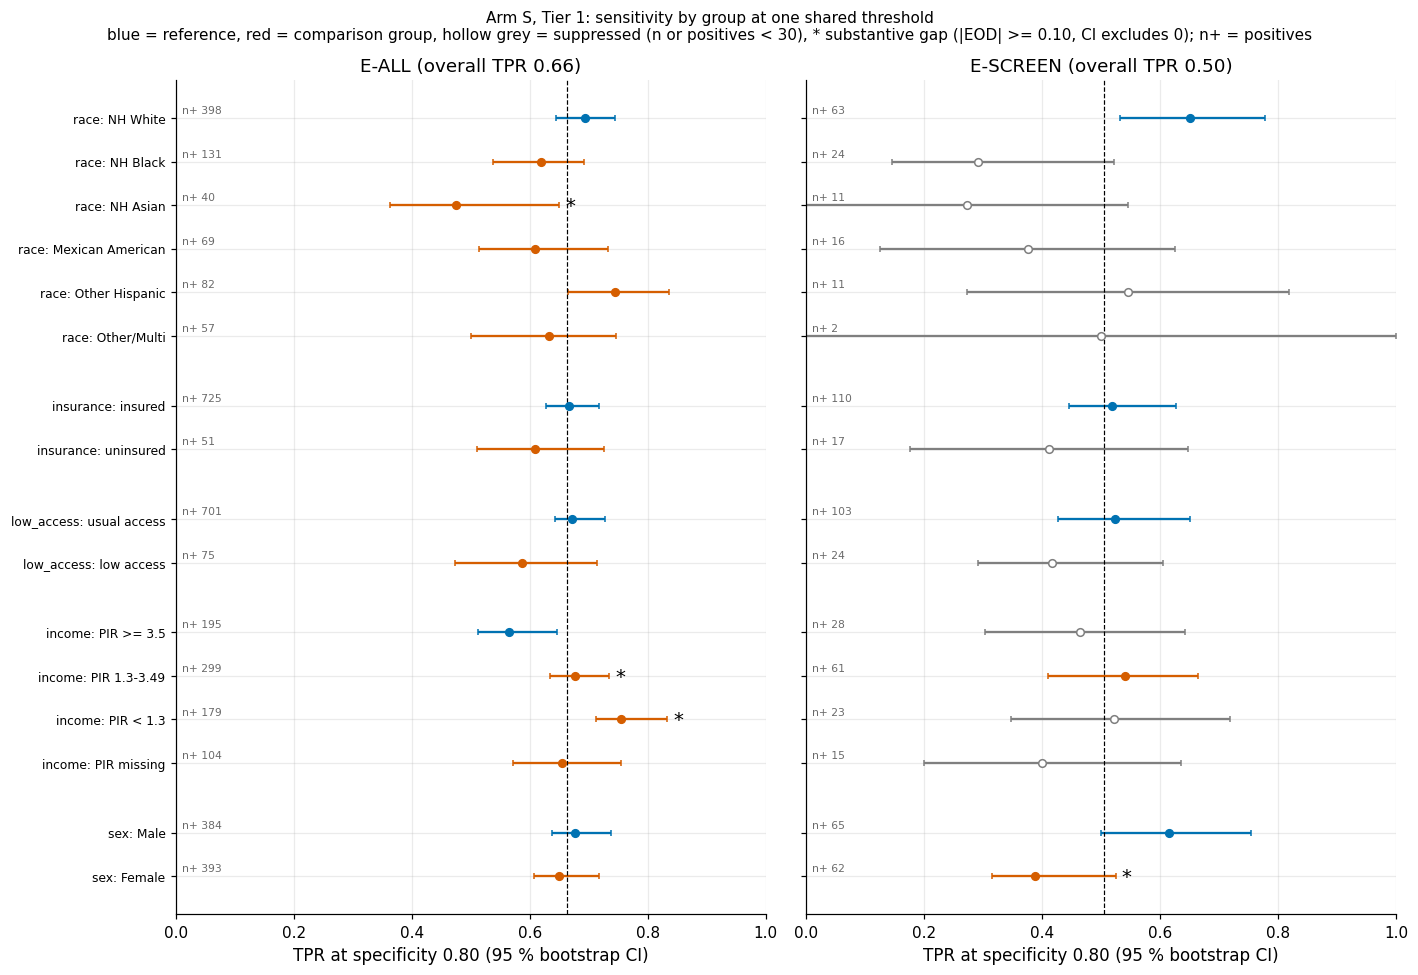

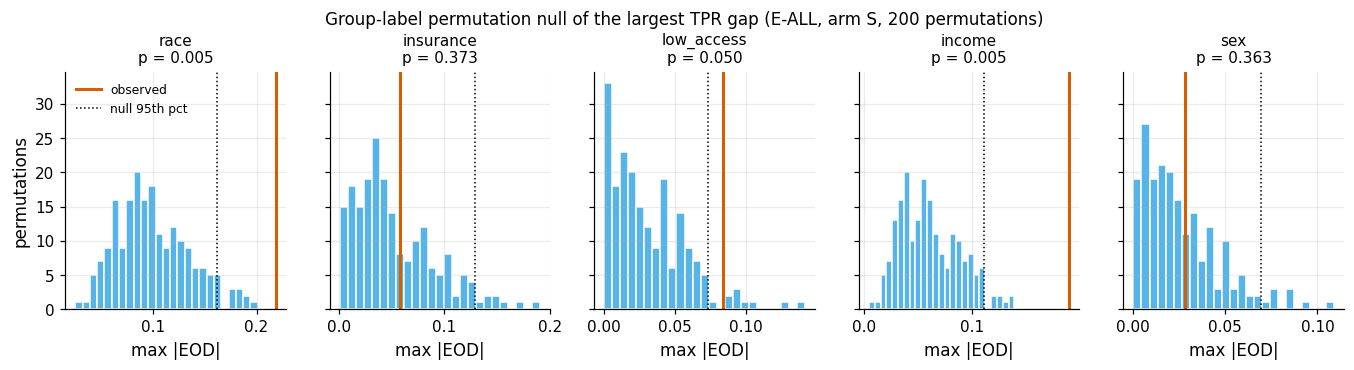

In [7]:
plots.set_style()
def tpr_panel(ax, GT, ET, title, overall):
    """Point-range of group TPRs; returns y labels (attribute: group)."""
    ylabels, ypos, k = [], [], 0
    for attr in F.ATTRIBUTES:
        g = GT[GT["attribute"] == attr]
        for _, r in g.iterrows():
            sup = r["status"] == "suppress"
            col = C.OKABE_ITO["grey"] if sup else (C.OKABE_ITO["blue"] if r["group"] == F.REFERENCE[attr] else C.OKABE_ITO["vermillion"])
            ax.errorbar(r["tpr"], -k, xerr=[[r["tpr"] - r["tpr_lo"]], [r["tpr_hi"] - r["tpr"]]], fmt="o",
                        color=col, mfc="white" if sup else col, capsize=2, ms=5)
            e = ET[(ET["attribute"] == attr) & (ET["group"] == r["group"])]
            if len(e) and bool(e["substantive"].iloc[0]) and e["verdict_status"].iloc[0] == "reportable":
                ax.annotate("*", (r["tpr_hi"], -k), xytext=(4, -4), textcoords="offset points", fontsize=13, color="black")
            ax.annotate(f"n+ {int(r['n_pos'])}", (0.01, -k), xytext=(0, 3), textcoords="offset points", fontsize=7, color="dimgrey")
            ylabels.append(f"{attr}: {r['group']}")
            ypos.append(-k)
            k += 1
        k += 0.6
    ax.axvline(overall, color="black", lw=0.8, ls="--")
    ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlabel("TPR at specificity 0.80 (95 % bootstrap CI)")
    ax.set_title(title)
    ax.set_xlim(0, 1)

# E-SCREEN tables are needed for the right panel (computed in section 4, re-used there)
GTs, ETs = tables("E-SCREEN", 1)
rec_s, _ = ek.recall_at_specificity(y_esc[esc], PM[("S", 1, "lr")][esc])
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
tpr_panel(axes[1], GTs, ETs, f"E-SCREEN (overall TPR {rec_s:.2f})", rec_s)
axes[1].tick_params(labelleft=False)
tpr_panel(axes[0], GT1, ET1, f"E-ALL (overall TPR {rec_check:.2f})", rec_check)
fig.suptitle("Arm S, Tier 1: sensitivity by group at one shared threshold\n"
             "blue = reference, red = comparison group, hollow grey = suppressed (n or positives < 30), * substantive gap (|EOD| >= 0.10, CI excludes 0); n+ = positives", fontsize=10)
fig.tight_layout()
f81 = plots.savefig(fig, "S8_group_tpr", caption="F8-1. TPR at specificity 0.80 by audit group for arm S (Tier 1) on E-ALL "
                    "and E-SCREEN, stratified bootstrap 95 % CI with the threshold re-estimated per replicate; dashed line = "
                    "overall TPR; hollow grey markers are suppressed cells (n < 30 or fewer than 30 positives).")
plt.show()

fig, axes = plt.subplots(1, len(F.ATTRIBUTES), figsize=(15, 2.8), sharey=True)
for ax, attr in zip(axes, F.ATTRIBUTES):
    row = PERM1.set_index("attribute").loc[attr]
    if attr in NULL1:
        ax.hist(NULL1[attr], bins=25, color=C.OKABE_ITO["sky"], edgecolor="white")
        ax.axvline(row["observed_max_eod"], color=C.OKABE_ITO["vermillion"], lw=2, label="observed")
        ax.axvline(row["null_q95"], color="black", ls=":", lw=1, label="null 95th pct")
        ax.set_title(f"{attr}\np = {row['p_value']:.3f}", fontsize=10)
    ax.set_xlabel("max |EOD|")
axes[0].set_ylabel("permutations"); axes[0].legend(fontsize=8)
fig.suptitle("Group-label permutation null of the largest TPR gap (E-ALL, arm S, 200 permutations)", fontsize=11, y=1.08)
f81b = plots.savefig(fig, "S8_permutation_null", caption="F8-1b. Null distribution of max |TPR_g - TPR_ref| over the reportable "
                     "groups when group labels are permuted 200 times (threshold fixed), with the observed value (red) "
                     "and the null 95th percentile (dotted). E-ALL, arm S, Tier 1.")
plt.show()
S8["group_metrics_eall_t1"] = GT1.round(5).to_dict("records")
S8["eod_eall_t1"] = ET1.round(5).to_dict("records")
S8["permutation_eall_t1"] = PERM1.round(5).to_dict("records")
S8["threshold_eall_t1"] = thr_eall
S8["overall_tpr_eall_t1"] = rec_check

**So what.** The left panel is the audit in one picture: the reference groups (blue) sit near the overall TPR, and the
comparison groups that deviate are those whose age structure differs. The permutation panel shows, per attribute,
whether the largest gap is beyond chance. A red line far to the right of the blue null means the attribute's largest
gap is real; a red line inside the null means the visible spread is what random grouping of the same people would
produce.

## 4 E-SCREEN
**Why.** E-SCREEN is the population the use case is about (adults not known to have diabetes). The same metrics are
computed with the threshold fixed at specificity 0.80 on the E-SCREEN negatives. With about 127 positives in total,
most groups have fewer than 30 positives; they are reported but receive no verdict.

In [8]:
PERMs, NULLs = permutation_block("E-SCREEN", 1)
print(f"E-SCREEN, Tier 1, arm S: overall TPR {rec_s:.3f}")
print(GTs[show].round(3).to_string(index=False))
print()
print(ETs[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print()
print(PERMs.round(3).to_string(index=False))
rep_s = ETs[ETs["verdict_status"].eq("reportable")]
print(f"\nreportable E-SCREEN gaps: {len(rep_s)} of {len(ETs)}; substantive among them: {int(rep_s['substantive'].sum())}")
S8["group_metrics_escreen_t1"] = GTs.round(5).to_dict("records")
S8["eod_escreen_t1"] = ETs.round(5).to_dict("records")
S8["permutation_escreen_t1"] = PERMs.round(5).to_dict("records")
S8["overall_tpr_escreen_t1"] = rec_s

E-SCREEN, Tier 1, arm S: overall TPR 0.504
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe   status                               flags
      race         NH White 2392     63 0.651   0.531   0.778 0.210 0.222 0.077 0.829   0.784   0.867 0.072  present                                    
      race         NH Black  433     24 0.292   0.145   0.522 0.227 0.231 0.070 0.643   0.576   0.719 0.145 suppress             n_pos<30;ci_width>=0.30
      race         NH Asian  223     11 0.273   0.000   0.545 0.123 0.130 0.103 0.806   0.713   0.892 0.179 suppress n_pos<30;ci_width>=0.30;exploratory
      race Mexican American  256     16 0.375   0.125   0.625 0.146 0.160 0.146 0.765   0.665   0.843 0.193 suppress             n_pos<30;ci_width>=0.30
      race   Other Hispanic  394     11 0.545   0.273   0.818 0.175 0.185 0.082 0.826   0.756   0.898 0.082 suppress             n_pos<30;ci_width>=0.30
      race      Other/Multi  236      2

**So what.** In the screening population only the sex contrast has two groups with 30 or more positives, and it shows
the one reportable screening gap: undiagnosed **women are found less often than undiagnosed men** (EOD and permutation p
printed above). A plausible route is body shape: the model rewards waist and penalises hip circumference, and women
have larger hips at the same waist. The race gaps look larger than on E-ALL (NH Black and NH Asian undiagnosed cases
are found far less often than White ones) but rest on 11–24 positives per group with CIs wider than 0.30, so they are
suppressed: a screening-population race audit is not possible with NHANES 2021–23. "Not reportable" here means
"not measurable", not "fair".

## 5 Tier 2 summary
**Why.** Tier 2 adds total and HDL cholesterol. If lipids carry group-specific information, the gaps could change. The
same audit is repeated on E-ALL and summarised by the largest reportable gap per attribute.

In [9]:
GT2, ET2 = tables("E-ALL", 2)
PERM2, _ = permutation_block("E-ALL", 2)
cmp_t = (ET1.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi", "verdict_status"]]
         .join(ET2.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi"]], rsuffix="_t2"))
cmp_t["delta_t2_t1"] = cmp_t["eod_t2"] - cmp_t["eod"]
print(cmp_t.round(3).to_string())
summ = PERM1.set_index("attribute")[["observed_max_eod", "p_value"]].join(
    PERM2.set_index("attribute")[["observed_max_eod", "p_value"]], rsuffix="_t2")
print("\nmax |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:")
print(summ.round(3).to_string())
max_shift = float(cmp_t["delta_t2_t1"].abs().max())
print(f"largest change of any EOD from Tier 1 to Tier 2: {max_shift:.3f}")
S8["tier2_summary"] = dict(eod=ET2.round(5).to_dict("records"), permutation=PERM2.round(5).to_dict("records"),
                           max_abs_eod_shift=max_shift)

                               eod  eod_lo  eod_hi verdict_status  eod_t2  eod_lo_t2  eod_hi_t2  delta_t2_t1
attribute  group                                                                                            
race       NH Black         -0.075  -0.171   0.013     reportable  -0.082     -0.163      0.020       -0.007
           NH Asian         -0.218  -0.352  -0.080     reportable  -0.164     -0.294      0.009        0.055
           Mexican American -0.085  -0.193   0.037     reportable  -0.101     -0.218      0.036       -0.016
           Other Hispanic    0.050  -0.043   0.155     reportable   0.030     -0.054      0.149       -0.021
           Other/Multi      -0.062  -0.190   0.068     reportable   0.016     -0.103      0.136        0.078
insurance  uninsured        -0.058  -0.170   0.064     reportable  -0.069     -0.192      0.072       -0.010
low_access low access       -0.084  -0.199   0.031     reportable  -0.123     -0.243     -0.009       -0.039
income     PIR 1.3-

**So what.** Adding lipids moves individual gaps by less than their own CIs (the largest shift is printed above); the
same groups stay on the same side of the reference. The attribute-level permutation p-values move around 0.05 for
race, income and low access between tiers, so the *ranking* of which attribute is "significant" is fragile, while
the direction of the gaps is not. Tier 1 remains the primary audit.

## 6 3 × 3 label matrix
**Why.** RQ3 asks whether the *label* decides who the model misses. Hypothesis H3 is pre-registered (`prior_exposure =
none`): train the identical arm-S pipeline (same folds, same steps, same C0, same class and survey weights) on three
labels – self-report `L_self`, HbA1c `L_A1c` and the frozen union `L_comb` – and score every model on three kinds of
diabetes: **D-uncontrolled** (self-report and HbA1c ≥ 6.5), **D-controlled** (self-report, HbA1c < 6.5 – treatment
masking) and **Undiagnosed** (HbA1c ≥ 6.5 without a diagnosis). Each cell is the recall at the threshold that gives
specificity 0.80 on the common non-diabetic negatives (the same negatives for all nine cells); AUC is secondary.
Locked prediction: `L_self` misses Undiagnosed most, `L_A1c` misses D-controlled most, `L_comb` has the smallest
worst-cell gap; differences below 0.05 count as equivalent.

Operational reading (fixed before looking at the matrix, coded in `fairness.h3_elements`): "misses most" is read
**column-wise** – among the three training labels, which one serves a given kind of diabetes worst, holding the
stratum and the negatives fixed; the worst-cell gap of a training label is its largest shortfall against the best
label in any column. Contrasts are paired bootstrap differences (the same resampled people for all rows) judged with
`evalkit.verdict` at SESOI 0.05. The matrix uses the training part (80 % of the 569 / 250 / 152 / 4,759 people
frozen in `label_freeze.md`); the hold-out stays untouched.

In [10]:
LABELS3 = ("L_self", "L_A1c", "L_comb")
YL = {lab: cl[lab].to_numpy().astype(int) for lab in LABELS3}
assert np.array_equal(YL["L_comb"], y)
from joblib import Parallel, delayed
t0 = time.time()
mk_S = lambda: P.build_pipeline(cfgS, 1, C_=C0)
new = Parallel(n_jobs=2)(delayed(ek.cv_predict)(mk_S, X1, YL[lab], folds, fit_params=fpS) for lab in ("L_self", "L_A1c"))
OOF3 = {"L_self": new[0], "L_A1c": new[1], "L_comb": OOF[("S", 1, "lr")]}
PM3 = {lab: ek.mean_oof(OOF3[lab], n) for lab in LABELS3}
cnt = pd.Series(strat).value_counts()
full = L.strata_counts(clean)
print(f"refitted arm S on L_self and L_A1c: {2 * len(folds)} fits, {time.time() - t0:.0f} s")
print("training-part strata (share of the frozen full-cohort counts):",
      {k: f"{int(cnt[k])} ({cnt[k] / full[k]:.2f})" for k in L.STRATA_3X3})
assert all(0.75 < cnt[k] / full[k] < 0.85 for k in L.STRATA_3X3)
LM = F.label_matrix(strat, PM3, n_boot=C.N_BOOT, seed=ek.derive_seed(C.SEED_MASTER, "S8", "3x3"))
cells = LM["cells"]
# consistency: L_comb row, Undiagnosed column = E-SCREEN recall of arm S (same positives, same negatives)
assert abs(LM["recall"].loc["L_comb", "Undiagnosed"] - rec_s) < 1e-12
print("\nrecall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):")
print(LM["recall"].round(3).to_string())
print("\nROC-AUC against the common negatives:")
print(LM["auc"].round(3).to_string())
print()
print(cells[["train_label", "stratum", "n_pos", "recall", "recall_lo", "recall_hi", "auc", "auc_lo", "auc_hi"]].round(3).to_string(index=False))
H3E = F.h3_elements(LM)
print("\npre-registered contrasts (predicted sign: negative):")
print(H3E.round(3).to_string(index=False))
# row-wise reading (secondary): in which stratum does each training label have its lowest recall?
roww = LM["recall"].idxmin(axis=1).to_dict()
print(f"\nrow-wise reading (secondary): lowest-recall stratum per training label {roww}")
gaps = F._worst_gap(LM["point"]["tpr"][0])
print("worst-cell gap per training label:", dict(zip(LABELS3, np.round(gaps, 3))))

refitted arm S on L_self and L_A1c: 20 fits, 11 s
training-part strata (share of the frozen full-cohort counts): {'D_uncontrolled': '455 (0.80)', 'D_controlled': '195 (0.78)', 'Undiagnosed': '127 (0.84)', 'NonDiabetic': '3807 (0.80)'}

recall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):
        D_uncontrolled  D_controlled  Undiagnosed
L_self           0.738         0.621        0.488
L_A1c            0.732         0.579        0.543
L_comb           0.736         0.595        0.504

ROC-AUC against the common negatives:
        D_uncontrolled  D_controlled  Undiagnosed
L_self           0.859         0.810        0.765
L_A1c            0.859         0.797        0.783
L_comb           0.862         0.809        0.779

train_label        stratum  n_pos  recall  recall_lo  recall_hi   auc  auc_lo  auc_hi
     L_self D_uncontrolled    455   0.738      0.687      0.778 0.859   0.844   0.875
     L_self   D_controlled    195   0.621      0.544      0.690 0

H3 element verdicts {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'} -> H3 inconclusive


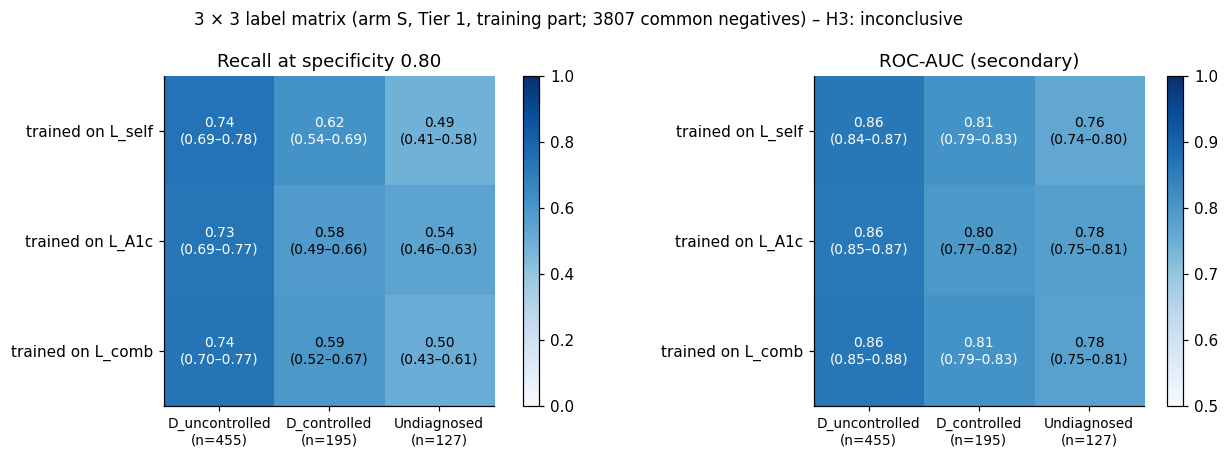

In [11]:
elem_v = {}
for el, g in H3E.groupby("element"):
    elem_v[el] = ek.combine_verdicts(g["verdict"].tolist())
h3_v = ek.combine_verdicts(list(elem_v.values()))
if H3E["reversed_ci_excl_0"].any():                       # locked falsifier
    h3_v = "refuted"
print(f"H3 element verdicts {elem_v} -> H3 {h3_v}")
cells.to_csv(OUT / "label_matrix_cells.csv", index=False)
H3E.to_csv(OUT / "h3_contrasts.csv", index=False)
S8["label_matrix"] = dict(cells=cells.round(5).to_dict("records"), recall=LM["recall"].round(5).to_dict(),
                          auc=LM["auc"].round(5).to_dict(), contrasts=H3E.round(5).to_dict("records"),
                          element_verdicts=elem_v, verdict=h3_v, row_wise_min=roww,
                          worst_gap=dict(zip(LABELS3, gaps.round(5))), strata_train=cnt.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, (mat, key, ttl) in zip(axes, [(LM["recall"], "recall", "Recall at specificity 0.80"), (LM["auc"], "auc", "ROC-AUC (secondary)")]):
    im = ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0 if key == "recall" else 0.5, vmax=1)
    for i, lab in enumerate(LABELS3):
        for j, st in enumerate(F.POS_STRATA):
            r = cells[(cells["train_label"] == lab) & (cells["stratum"] == st)].iloc[0]
            v = mat.loc[lab, st]
            ax.text(j, i, f"{v:.2f}\n({r[key + '_lo']:.2f}–{r[key + '_hi']:.2f})", ha="center", va="center",
                    fontsize=9, color="white" if v > (0.6 if key == "recall" else 0.8) else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{s}\n(n={int(cnt[s])})" for s in F.POS_STRATA], fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels([f"trained on {l}" for l in LABELS3])
    ax.set_title(ttl); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"3 × 3 label matrix (arm S, Tier 1, training part; {int(cnt['NonDiabetic'])} common negatives) – H3: {h3_v}", fontsize=11)
fig.tight_layout()
f82 = plots.savefig(fig, "S8_label_matrix", caption="F8-2. 3x3 label matrix: arm S trained on L_self, L_A1c or L_comb "
                    "(identical folds, steps and C0) and scored on D-uncontrolled, D-controlled and Undiagnosed cases against "
                    "the common NonDiabetic negatives. Left: recall at specificity 0.80 with 95 % stratified bootstrap CI "
                    "(thresholds re-estimated per replicate); right: ROC-AUC.")
plt.show()

**So what.** Every element of the locked pattern points the predicted way: in the Undiagnosed column the
self-report model has the lowest recall, in the D-controlled column the HbA1c-only model has the lowest recall, and
the union label has the smallest worst-cell gap. But the differences are small – a few percentage points, at most
about 0.06 – and every paired CI includes 0 while also reaching beyond ±0.05, so H3 is **inconclusive**: neither the
predicted ordering nor equivalence is established (verdict line above). The row-wise reading tells the stronger
story: *whatever* the training label, the Undiagnosed column is the hardest, and the AUCs show the same order. With
non-laboratory features the model cannot see the diagnosis gap: undiagnosed people lack the care traces and the
treatment-era profile that the features pick up, and changing the label only moves the threshold marginally. The
label therefore shapes *what the model claims to measure* (§5 counts: 152 vs 250 people silently dropped by the two
single labels) more than *whom this feature set can find*.

## 7 Access-proxy audit arm
**Why.** §5 found that uninsured adults and adults without a usual place of care are more often undiagnosed. If the
self-report label carries this access imprint, a model trained on `L_self` should learn that *lacking access lowers
the chance of "having diabetes"* – a pure artefact of who gets diagnosed – while a model trained on the union label
(or on HbA1c, which needs no doctor) should not. The audit arm adds two binary features, **uninsured** (HIQ011 = 2)
and **no usual place of care** (HUQ030 = 2), to the arm-S pipeline and fits it on each label. Coefficients (per SD,
because P09 scales every column) are bootstrapped with `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); the
same seed gives the same resampled rows for every label, so differences between labels are paired. This arm is an
**audit instrument only**: the availability rule keeps insurance and access out of every model that could be used.

In [12]:
t0 = time.time()
mk_acc = lambda: F.access_pipeline(cfgS, 1, C_=C0)
assert set(F.ACCESS_FEATURES) <= set(mk_acc()[:-1].fit(X1.iloc[:500], y[:500]).get_feature_names_out())
seed_acc = ek.derive_seed(C.SEED_MASTER, "S8", "access_audit")
CB = {lab: ek.coef_bootstrap(mk_acc, X1, YL[lab], n_boot=C.N_BOOT_COEF, seed=seed_acc, fit_params=fpS, n_jobs=N_JOBS)
      for lab in LABELS3}
sd_bin = {f: float(np.sqrt(grp[f].fillna(0).mean() * (1 - grp[f].fillna(0).mean()))) for f in F.ACCESS_FEATURES}
acc_rows = []
for f in F.ACCESS_FEATURES:
    for lab in LABELS3:
        s_ = CB[lab].summary.loc[f]
        acc_rows.append({"feature": f, "label": lab, "coef_per_sd": s_["coef"], "lo": s_["q_low"], "hi": s_["q_high"],
                         "boot_sd": s_["sd"], "OR_yes_vs_no": np.exp(s_["coef"] / sd_bin[f]),
                         "OR_lo": np.exp(s_["q_low"] / sd_bin[f]), "OR_hi": np.exp(s_["q_high"] / sd_bin[f])})
ACC = pd.DataFrame(acc_rows)
diff_rows = []
for f in F.ACCESS_FEATURES:
    for a, b in (("L_self", "L_comb"), ("L_self", "L_A1c"), ("L_comb", "L_A1c")):
        d = CB[a].coefs[f].to_numpy() - CB[b].coefs[f].to_numpy()
        e, lo, hi, se = F.summarise(CB[a].summary.loc[f, "coef"] - CB[b].summary.loc[f, "coef"], d)
        diff_rows.append({"feature": f, "contrast": f"{a} - {b}", "diff_per_sd": e, "lo": lo, "hi": hi,
                          "ci_excludes_0": bool(lo > 0 or hi < 0)})
ACCD = pd.DataFrame(diff_rows)
print(f"access audit arm: {len(LABELS3)} labels x (1 + {C.N_BOOT_COEF}) fits, {time.time() - t0:.0f} s")
print(ACC.round(3).to_string(index=False))
print("\npaired differences of the per-SD coefficient between training labels:")
print(ACCD.round(3).to_string(index=False))
ACC.to_csv(OUT / "access_audit_coefs.csv", index=False)
ACCD.to_csv(OUT / "access_audit_diffs.csv", index=False)
S8["access_audit"] = dict(coefs=ACC.round(5).to_dict("records"), diffs=ACCD.round(5).to_dict("records"),
                          n_boot=C.N_BOOT_COEF, sd_binary=sd_bin)

access audit arm: 3 labels x (1 + 100) fits, 25 s
       feature  label  coef_per_sd     lo     hi  boot_sd  OR_yes_vs_no  OR_lo  OR_hi
     uninsured L_self       -0.112 -0.271  0.020    0.079         0.669  0.379  1.073
     uninsured  L_A1c        0.016 -0.148  0.148    0.076         1.057  0.589  1.700
     uninsured L_comb       -0.012 -0.165  0.127    0.075         0.958  0.554  1.578
no_usual_place L_self       -0.203 -0.391 -0.085    0.086         0.526  0.289  0.764
no_usual_place  L_A1c       -0.095 -0.249  0.032    0.074         0.741  0.454  1.108
no_usual_place L_comb       -0.099 -0.231  0.020    0.066         0.731  0.480  1.066

paired differences of the per-SD coefficient between training labels:
       feature        contrast  diff_per_sd     lo     hi  ci_excludes_0
     uninsured L_self - L_comb       -0.100 -0.199 -0.012           True
     uninsured  L_self - L_A1c       -0.128 -0.267  0.006          False
     uninsured  L_comb - L_A1c       -0.028 -0.090  0.027 

**So what.** The access imprint is visible exactly where the label requires a doctor. Trained on self-report, the
model gives both access features negative coefficients – lacking insurance or a usual place of care *lowers* the
predicted chance of diabetes – although §5 showed that diabetes itself is not rarer in these groups once age is
accounted for. Trained on HbA1c, which needs no diagnosis, the coefficients are close to zero; the union label sits in
between, much closer to HbA1c. The paired differences (self-report minus union) are negative for both features, with
the CI excluding 0 for at least one of them (table above). A model trained on self-report would therefore learn to
**score people with poor access as lower risk because they were never diagnosed** – a feedback loop that would deepen
the diagnosis gap. This is the strongest model-level evidence in the project that the label is a measurement of
access as well as of disease, and it supports both the frozen union label and the decision to keep insurance and
access out of the model.

## 8 Reweighing
**Why.** Reweighing (Kamiran & Calders 2012) is the standard pre-processing mitigation: each training row gets the
weight w(g, y) = P(g)·P(y) / P(g, y), which makes group and label independent in the weighted training data without
touching features or predictions. It is applied **inside every training fold** (weights computed from that fold's rows)
on top of the survey weights of arm S, so the comparison with S is paired on the same folds. Three versions are run:
race (pre-specified, expected to do almost nothing because the race groups differ little in prevalence in this cycle),
and – as extension items – insurance and low access, the attributes linked to the diagnosis gap. ΔAUC uses the locked
S7 engine (E-ALL: the wider of the corrected-t and paired-bootstrap intervals; E-SCREEN: paired bootstrap); the gap
changes are paired bootstrap differences of EOD with the threshold re-estimated for each arm.

In [13]:
from joblib import parallel_config
from sklearn.metrics import roc_auc_score
from scipy import stats as sstats

def fold_auc(oof, pop="E-ALL"):
    yy, m = pop_of(pop)
    out = {}
    for (r, f), g in oof.groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        k = m[rows]
        out[(r, f)] = roc_auc_score(yy[rows][k], g["prob"].to_numpy()[k])
    return pd.Series(out)

def compare_auc(oof_a, oof_b, pop="E-ALL", tag=""):
    """Paired ΔAUC A - B: E-ALL wider of corrected t and paired bootstrap; E-SCREEN bootstrap only (locked S7 rules)."""
    yy, m = pop_of(pop)
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    bs = ek.paired_bootstrap(yy, pa, pb, "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S8", "dauc", tag, pop))
    row = dict(pop=pop, diff_pooled=bs["diff"], boot_lo=bs["ci_low"], boot_hi=bs["ci_high"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    if pop == "E-ALL":
        ct = ek.corrected_t((fold_auc(oof_a) - fold_auc(oof_b)).to_numpy(), n_train_fold, n_test_fold)
        row.update(t_lo=ct["ci_low"], t_hi=ct["ci_high"])
        if ct["ci_high"] - ct["ci_low"] >= hi - lo:
            est, lo, hi, se, interval = ct["mean"], ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=(sstats.norm.ppf(0.975) + sstats.norm.ppf(0.8)) * se)
    return row

RW_TARGET = {"race": "NH Asian", "insurance": "uninsured", "low_access": "low access"}
OOF_RW, RW_W, RW_ROWS, RW_EOD = {}, {}, [], []
t0 = time.time()
with parallel_config(max_nbytes=None):
    for attr in RW_TARGET:
        gvals = grp[attr].to_numpy(dtype=object)
        w_rw = F.reweighing_weights(gvals, y)
        RW_W[attr] = w_rw
        OOF_RW[attr] = F.cv_predict_reweighed(mk_S, X1, y, folds, gvals, base_weight=w_svy, n_jobs=N_JOBS)
print(f"reweighing arms: {len(RW_TARGET)} x {len(folds)} fits, {time.time() - t0:.0f} s")
for attr, w_rw in RW_W.items():
    lv = grp[attr].fillna("(unknown)")
    tab = pd.DataFrame({"g": lv, "y": y, "w": w_rw}).groupby(["g", "y"])["w"].first().unstack()
    print(f"\n{attr}: reweighing weights w(g, y) on the training part (range {w_rw.min():.3f}-{w_rw.max():.3f})")
    print(tab.round(3).rename(columns={0: "w(y=0)", 1: "w(y=1)"}).to_string())
    PMx = ek.mean_oof(OOF_RW[attr], n)
    for pop in ("E-ALL", "E-SCREEN"):
        r = compare_auc(OOF_RW[attr], OOF[("S", 1, "lr")], pop, tag=f"rw_{attr}")
        r.update(arm=f"S+RW({attr})", w_min=w_rw.min(), w_max=w_rw.max(),
                 verdict_auc=("equivalent" if (r["lo"] > -0.01 and r["hi"] < 0.01) else
                              ek.verdict(r["lo"], r["hi"], 0.01, "+", r["est"])))
        RW_ROWS.append(r)
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S", "RW"), preds={"RW": PMx})
    lvls = F.LEVELS[attr]
    ref = lvls.index(F.REFERENCE[attr])
    for g_i, g_nm in enumerate(lvls):
        if g_i == ref:
            continue
        eod_pt = point["tpr"][0, :, g_i] - point["tpr"][0, :, ref]
        eod_bt = boot["tpr"][:, :, g_i] - boot["tpr"][:, :, ref]
        e, lo, hi, _ = F.summarise(eod_pt[1] - eod_pt[0], eod_bt[:, 1] - eod_bt[:, 0])
        ea, alo, ahi, _ = F.summarise(abs(eod_pt[1]) - abs(eod_pt[0]), np.abs(eod_bt[:, 1]) - np.abs(eod_bt[:, 0]))
        RW_EOD.append({"arm": f"S+RW({attr})", "attribute": attr, "group": g_nm, "eod_S": eod_pt[0], "eod_RW": eod_pt[1],
                       "d_eod": e, "d_eod_lo": lo, "d_eod_hi": hi, "d_abs_eod": ea, "d_abs_lo": alo, "d_abs_hi": ahi,
                       "target": g_nm == RW_TARGET[attr]})
RWT = pd.DataFrame(RW_ROWS)
RWE = pd.DataFrame(RW_EOD)
print("\nΔAUC reweighed arm − S:")
print(RWT[["arm", "pop", "est", "lo", "hi", "interval", "mdd", "w_min", "w_max", "verdict_auc"]].round(4).to_string(index=False))
print("\nchange of equal-opportunity differences (reweighed − S), E-ALL:")
print(RWE.round(3).to_string(index=False))
RWT.to_csv(OUT / "reweighing_auc.csv", index=False)
RWE.to_csv(OUT / "reweighing_eod.csv", index=False)
S8["reweighing"] = dict(auc=RWT.round(5).to_dict("records"), eod=RWE.round(5).to_dict("records"),
                        weight_range={a: [float(w.min()), float(w.max())] for a, w in RW_W.items()})

reweighing arms: 3 x 10 fits, 15 s

race: reweighing weights w(g, y) on the training part (range 0.699-1.161)
y                 w(y=0)  w(y=1)
g                               
Mexican American   1.069   0.759
NH Asian           0.987   1.068
NH Black           1.097   0.699
NH White           0.972   1.161
Other Hispanic     1.008   0.961
Other/Multi        1.033   0.865



insurance: reweighing weights w(g, y) on the training part (range 0.949-1.356)
y          w(y=0)  w(y=1)
g                        
(unknown)   0.949   1.356
insured     1.004   0.979
uninsured   0.955   1.296



low_access: reweighing weights w(g, y) on the training part (range 0.678-1.677)
y             w(y=0)  w(y=1)
g                           
(unknown)      1.107   0.678
low access     0.924   1.677
usual access   1.016   0.928



ΔAUC reweighed arm − S:
             arm      pop     est      lo     hi    interval    mdd  w_min  w_max verdict_auc
      S+RW(race)    E-ALL -0.0004 -0.0026 0.0017 corrected_t 0.0027 0.6987 1.1614  equivalent
      S+RW(race) E-SCREEN -0.0010 -0.0046 0.0021   bootstrap 0.0049 0.6987 1.1614  equivalent
 S+RW(insurance)    E-ALL  0.0002 -0.0007 0.0010 corrected_t 0.0011 0.9491 1.3560  equivalent
 S+RW(insurance) E-SCREEN  0.0020  0.0009 0.0030   bootstrap 0.0018 0.9491 1.3560  equivalent
S+RW(low_access)    E-ALL -0.0001 -0.0023 0.0020 corrected_t 0.0027 0.6780 1.6769  equivalent
S+RW(low_access) E-SCREEN  0.0044  0.0011 0.0075   bootstrap 0.0045 0.6780 1.6769  equivalent

change of equal-opportunity differences (reweighed − S), E-ALL:
             arm  attribute            group  eod_S  eod_RW  d_eod  d_eod_lo  d_eod_hi  d_abs_eod  d_abs_lo  d_abs_hi  target
      S+RW(race)       race         NH Black -0.075  -0.126 -0.051    -0.100    -0.008      0.051     0.008     0.097   False


**So what.** Reweighing is a null mitigation here, and an instructive one. The weights are not close to 1 for race
(NH Black cases are down-weighted to about 0.7 because their prevalence is highest), yet discrimination does not move:
every ΔAUC interval lies inside ±0.01 (equivalent) on both populations. The gaps do not close either: the NH Asian gap
changes by a few points with a CI spanning zero, and race reweighing *widens* the NH Black gap, because making race
and label independent removes exactly the prevalence difference that made Black cases easier to find. Insurance and
low-access reweighing narrow their gaps a little, with CIs that include 0. Reweighing acts on the label–group
association; the gaps found in section 3 come from features (care traces, BMI) and from the label's diagnosis
component, which reweighing does not touch.

## 9 WHtR measurement fix (P14-b)
**Why.** §5 found that BMI under-reads adiposity in Asian adults (single-feature AUC gain of WHtR over BMI +0.137 for
Asian against +0.049 for White adults), and section 3 found Asian cases missed most at the shared threshold, mainly
because they are leaner. Arm S+WHtR replaces waist circumference by waist-to-height ratio (P14, pre-registered in S6;
`prior_exposure = descriptive_seen`). Locked prediction **P14-b**: Asian TPR at specificity 0.80 rises by at least
0.05 (falsifier: upper CI bound of ΔTPR below 0.05), overall |ΔAUC| < 0.01 (P14-a, tested in §7), and the White
change is smaller (control group). With only 40 Asian positives in the training part, two intervals are computed: the
simple stratified bootstrap and a **PSU-cluster bootstrap** (Rao–Wu, `survey.rao_wu_weights`), because Asian adults
cluster in few PSUs; the wider interval decides. The model-level counterpart of H4b (does the WHtR advantage
transfer into the multivariable model, Asian more than White?) is read from the same replicates as the within-group
ΔAUC.

In [14]:
pW = PM[("S+WHtR", 1, "lr")]
res = {}
for wt in ("simple", "psu"):
    point, boot, codes, mm = audit("race", "E-ALL", 1, ("S", "S+WHtR"), weights=wt)
    res[wt] = (point, boot)
lv = F.LEVELS["race"]
iA, iW = lv.index("NH Asian"), lv.index("NH White")
whtr_rows = []
def add_whtr(name, pt_fn):
    row = {"quantity": name}
    for wt in ("simple", "psu"):
        point, boot = res[wt]
        e, lo, hi, se = F.summarise(pt_fn(point)[0], pt_fn(boot))
        bvals = np.asarray(pt_fn(boot), float)
        row.update({"est": e, f"{wt}_lo": lo, f"{wt}_hi": hi, f"{wt}_se": se, f"{wt}_boot_mean": float(np.nanmean(bvals))})
    wide = "psu" if (row["psu_hi"] - row["psu_lo"]) >= (row["simple_hi"] - row["simple_lo"]) else "simple"
    row.update(lo=row[f"{wide}_lo"], hi=row[f"{wide}_hi"], interval=wide)
    whtr_rows.append(row)
    return row
r_tA = add_whtr("TPR NH Asian, S", lambda d: d["tpr"][:, 0, iA])
r_tA2 = add_whtr("TPR NH Asian, S+WHtR", lambda d: d["tpr"][:, 1, iA])
r_tW = add_whtr("TPR NH White, S", lambda d: d["tpr"][:, 0, iW])
r_tW2 = add_whtr("TPR NH White, S+WHtR", lambda d: d["tpr"][:, 1, iW])
r_dA = add_whtr("ΔTPR NH Asian", lambda d: d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA])
r_dW = add_whtr("ΔTPR NH White", lambda d: d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW])
r_dd = add_whtr("ΔTPR Asian − ΔTPR White", lambda d: (d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA]) - (d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW]))
r_eod = add_whtr("Δ|EOD| Asian vs White", lambda d: np.abs(d["tpr"][:, 1, iA] - d["tpr"][:, 1, iW]) - np.abs(d["tpr"][:, 0, iA] - d["tpr"][:, 0, iW]))
r_auc = add_whtr("ΔAUC overall", lambda d: d["auc_all"][:, 1] - d["auc_all"][:, 0])
r_aA = add_whtr("ΔAUC within NH Asian", lambda d: d["auc"][:, 1, iA] - d["auc"][:, 0, iA])
r_aW = add_whtr("ΔAUC within NH White", lambda d: d["auc"][:, 1, iW] - d["auc"][:, 0, iW])
r_h4 = add_whtr("ΔAUC Asian − ΔAUC White (H4b, model level)", lambda d: (d["auc"][:, 1, iA] - d["auc"][:, 0, iA]) - (d["auc"][:, 1, iW] - d["auc"][:, 0, iW]))
WH = pd.DataFrame(whtr_rows)
print(WH[["quantity", "est", "simple_lo", "simple_hi", "simple_boot_mean", "psu_lo", "psu_hi", "psu_boot_mean", "interval"]].round(3).to_string(index=False))
# E-SCREEN (secondary; NH Asian has 11 positives -> suppressed, numbers only)
pt_s, bt_s, _, _ = audit("race", "E-SCREEN", 1, ("S", "S+WHtR"))
dA_s = F.summarise(pt_s["tpr"][0, 1, iA] - pt_s["tpr"][0, 0, iA], bt_s["tpr"][:, 1, iA] - bt_s["tpr"][:, 0, iA])
print(f"\nE-SCREEN (suppressed, {int(pt_s['n_pos'][0, 0, iA])} Asian positives): ΔTPR NH Asian {dA_s[0]:+.3f} ({dA_s[1]:+.3f}, {dA_s[2]:+.3f})")
p14a = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "P14" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
print(f"P14-a from §7 (E-ALL, corrected t): ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}) -> {p14a['verdict']}")

                                  quantity    est  simple_lo  simple_hi  simple_boot_mean  psu_lo  psu_hi  psu_boot_mean interval
                           TPR NH Asian, S  0.475      0.362      0.650             0.497   0.286   0.696          0.501      psu
                      TPR NH Asian, S+WHtR  0.550      0.375      0.675             0.544   0.320   0.690          0.537      psu
                           TPR NH White, S  0.693      0.644      0.744             0.697   0.650   0.763          0.701      psu
                      TPR NH White, S+WHtR  0.704      0.647      0.745             0.701   0.660   0.758          0.705      psu
                             ΔTPR NH Asian  0.075      0.000      0.163             0.047  -0.071   0.103          0.036      psu
                             ΔTPR NH White  0.010     -0.016      0.028             0.004  -0.021   0.027          0.003      psu
                   ΔTPR Asian − ΔTPR White  0.065     -0.018      0.147             0.043 

P14-b: ΔTPR NH Asian +0.075 (-0.071, +0.103; psu interval) -> inconclusive; White control |Δ| smaller: True
P14 overall (a: supported, b: inconclusive) -> inconclusive
H4b model level: +0.004 (-0.003, +0.011) -> inconclusive; S5 single-feature verdict supported -> H4b supported


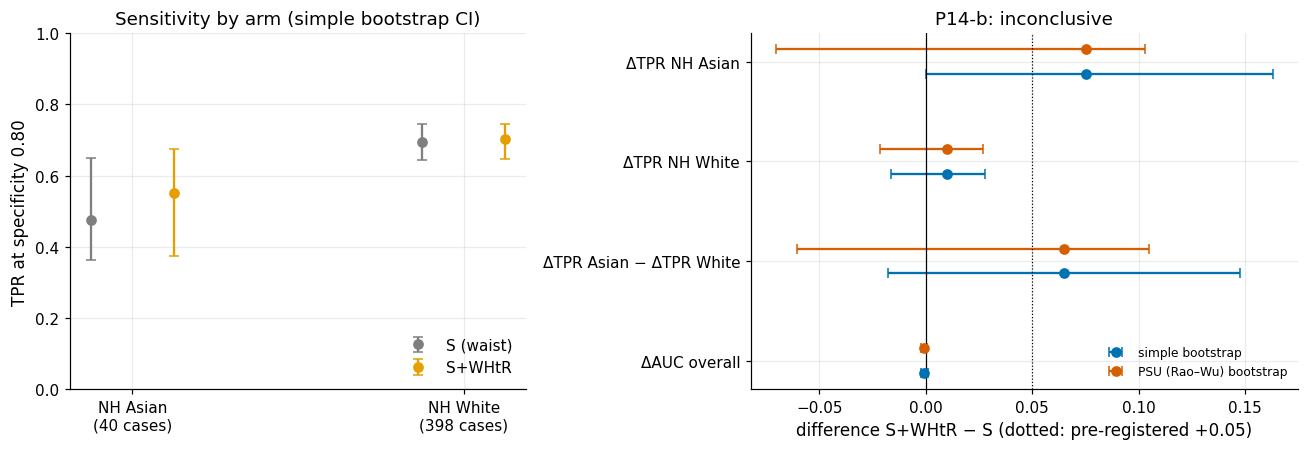

In [15]:
v_p14b = ek.verdict(r_dA["lo"], r_dA["hi"], 0.05, "+", r_dA["est"])
v_p14b = "refuted" if (v_p14b == "equivalent" or r_dA["hi"] < 0.05) else v_p14b     # locked falsifier
control_ok = abs(r_dW["est"]) < abs(r_dA["est"])
v_p14 = ek.combine_verdicts([p14a["verdict"], v_p14b])
v_h4b_model = ("supported" if (r_h4["lo"] > 0 and r_h4["est"] >= 0.01) else
               "refuted" if r_h4["hi"] < 0 else "inconclusive")
s5_h4b = R.load_section("S5")["hypotheses"]["H4b"]["verdict"]
v_h4b = "mixed" if (s5_h4b in ("supported", "refuted") and v_h4b_model in ("supported", "refuted") and v_h4b_model != s5_h4b) else s5_h4b
print(f"P14-b: ΔTPR NH Asian {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}; {r_dA['interval']} interval) -> {v_p14b}; "
      f"White control |Δ| smaller: {control_ok}")
print(f"P14 overall (a: {p14a['verdict']}, b: {v_p14b}) -> {v_p14}")
print(f"H4b model level: {r_h4['est']:+.3f} ({r_h4['lo']:+.3f}, {r_h4['hi']:+.3f}) -> {v_h4b_model}; S5 single-feature verdict "
      f"{s5_h4b} -> H4b {v_h4b}")
WH.to_csv(OUT / "whtr_p14b.csv", index=False)
S8["whtr"] = dict(table=WH.round(5).to_dict("records"), p14b_verdict=v_p14b, p14_verdict=v_p14, white_control_smaller=control_ok,
                  p14a_from_S7={k: p14a[k] for k in ("est", "lo", "hi", "verdict")}, h4b_model_verdict=v_h4b_model,
                  h4b_s5_verdict=s5_h4b, h4b_verdict=v_h4b, escreen_dtpr_asian=list(dA_s[:3]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for j, (nm, a, b) in enumerate([("NH Asian", r_tA, r_tA2), ("NH White", r_tW, r_tW2)]):
    for k_, (r_, col, lab) in enumerate([(a, C.OKABE_ITO["grey"], "S (waist)"), (b, C.OKABE_ITO["orange"], "S+WHtR")]):
        x = j + (k_ - 0.5) * 0.25
        ax.errorbar(x, r_["est"], yerr=[[r_["est"] - r_["simple_lo"]], [r_["simple_hi"] - r_["est"]]], fmt="o", color=col,
                    capsize=3, label=lab if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"NH Asian\n({int(res['simple'][0]['n_pos'][0, 0, iA])} cases)",
                                            f"NH White\n({int(res['simple'][0]['n_pos'][0, 0, iW])} cases)"])
ax.set_ylabel("TPR at specificity 0.80"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Sensitivity by arm (simple bootstrap CI)")
ax = axes[1]
qs = ["ΔTPR NH Asian", "ΔTPR NH White", "ΔTPR Asian − ΔTPR White", "ΔAUC overall"]
for i, q in enumerate(qs):
    r_ = WH.set_index("quantity").loc[q]
    for k_, (wt, col) in enumerate([("simple", C.OKABE_ITO["blue"]), ("psu", C.OKABE_ITO["vermillion"])]):
        ax.errorbar(r_["est"], -i + (k_ - 0.5) * 0.25, xerr=[[r_["est"] - r_[f"{wt}_lo"]], [r_[f"{wt}_hi"] - r_["est"]]],
                    fmt="o", color=col, capsize=3, label=("simple bootstrap" if wt == "simple" else "PSU (Rao–Wu) bootstrap") if i == 0 else None)
ax.axvline(0, color="black", lw=0.8); ax.axvline(0.05, color="black", lw=0.8, ls=":")
ax.set_yticks([-i for i in range(len(qs))]); ax.set_yticklabels(qs)
ax.set_xlabel("difference S+WHtR − S (dotted: pre-registered +0.05)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"P14-b: {v_p14b}")
fig.tight_layout()
f83 = plots.savefig(fig, "S8_whtr_asian_white", caption="F8-3. WHtR measurement fix (arm S+WHtR vs S, E-ALL, Tier 1): TPR at "
                    "specificity 0.80 for NH Asian and NH White adults (left) and the paired changes with simple stratified and "
                    "PSU-cluster (Rao-Wu) bootstrap 95 % CIs (right); dotted line = pre-registered minimum gain of 0.05.")
plt.show()

**So what.** The measurement fix moves the right group in the right direction: NH Asian sensitivity rises by about 0.07
while White sensitivity barely changes, overall discrimination is unchanged (P14-a equivalent in §7, ΔAUC about
−0.001 here), and the Asian–White gap narrows. But with 40 Asian cases the interval is wide – the PSU-cluster bootstrap,
which respects that Asian adults are concentrated in few PSUs, is wider than the simple one and reaches well below
0.05 – so the pre-registered P14-b is **inconclusive**, not supported. At model level the WHtR advantage that §5 saw
for a single feature (H4b) largely disappears: the model already contains waist, height and BMI, so replacing waist by
their ratio adds little ranking information (within-group ΔAUC near 0). WHtR is therefore *not* adopted as a new
preparation step and loop L4 is not triggered; the result is reported as a promising but underpowered direction.

## 10 Group-specific thresholds
**Why.** The obvious "fix" for a TPR gap is a lower threshold for the disadvantaged group (Hardt et al. 2016 post-
processing). It is **not** implemented, for three reasons recorded in R7.2: (i) it requires race at prediction time,
i.e. explicit differential treatment by a protected attribute, which the availability rule and the governance scope
exclude; (ii) it can equalise TPR only by raising the group's false positives or by lowering other groups' TPR
("levelling down", Fairlearn ThresholdOptimizer documentation); (iii) with about 40 Asian cases the group threshold
would be unstable. Point (iii) is quantified here: the Asian-specific threshold that would give NH Asian adults the
White TPR, and the false-positive rate it implies, with bootstrap CIs.

In [16]:
def asian_threshold(w=None):
    w = np.ones(n) if w is None else w
    a_pos, a_neg = (grp["race"].eq("NH Asian").to_numpy() & (y == 1)), (grp["race"].eq("NH Asian").to_numpy() & (y == 0))
    w_pos = (grp["race"].eq("NH White").to_numpy() & (y == 1))
    hit = pS >= thr_check
    tpr_w = np.average(hit[w_pos], weights=w[w_pos])
    s_ = np.sort(pS[a_pos]); ww = w[a_pos][np.argsort(pS[a_pos])]
    cum = np.cumsum(ww[::-1])[::-1] / ww.sum()          # share of Asian cases at or above each score
    k = np.flatnonzero(cum >= tpr_w - 1e-12).max()
    t_a = s_[k]
    fpr_a = np.average(pS[a_neg] >= t_a, weights=w[a_neg])
    return t_a, fpr_a, tpr_w
t_a, fpr_a, tpr_w = asian_threshold()
Wst = F.stratified_counts((grp["race"].astype(str) + "|" + pd.Series(y).astype(str)).to_numpy(), C.N_BOOT, ek.derive_seed(C.SEED_MASTER, "S8", "gthr"))
bt = np.array([asian_threshold(Wst[b])[:2] for b in range(len(Wst))])
fpr_overall_a = float(GT1.set_index(["attribute", "group"]).loc[("race", "NH Asian"), "fpr"])
GTHR = dict(threshold_overall=thr_check, threshold_asian=t_a, threshold_asian_ci=list(np.percentile(bt[:, 0], [2.5, 97.5])),
            fpr_asian_at_own=fpr_a, fpr_asian_at_own_ci=list(np.percentile(bt[:, 1], [2.5, 97.5])), fpr_asian_at_shared=fpr_overall_a,
            tpr_white=tpr_w)
print(f"shared threshold {thr_check:.3f}; Asian threshold matching the White TPR ({tpr_w:.3f}): {t_a:.3f} "
      f"(95 % CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f})")
print(f"Asian FPR: {fpr_overall_a:.3f} at the shared threshold -> {fpr_a:.3f} at the group threshold "
      f"(95 % CI {GTHR['fpr_asian_at_own_ci'][0]:.3f}-{GTHR['fpr_asian_at_own_ci'][1]:.3f})")
S8["group_threshold_counterfactual"] = GTHR

shared threshold 0.639; Asian threshold matching the White TPR (0.693): 0.541 (95 % CI 0.416-0.630)
Asian FPR: 0.123 at the shared threshold -> 0.175 at the group threshold (95 % CI 0.113-0.279)


**So what.** Matching the White TPR would need a markedly lower threshold for Asian adults, would raise their
false-positive rate by about half, and the threshold itself has a wide interval because it rests on about 40 cases
(numbers above).
The project therefore keeps one threshold for everybody and treats the Asian gap as a **measurement** problem (section
9) and a **data** problem (too few Asian cases in this cycle), not as something to be patched at the decision step.

## 11 Fairness–performance trade-off
**Why.** A mitigation is only worth adopting if it narrows a gap without costing discrimination. The four mitigation
arms are placed in one plane: x = ΔAUC against S on E-ALL (locked S7 interval: the wider of corrected t and paired
bootstrap), y = change of the absolute gap |EOD| for the group each mitigation targets (paired bootstrap, threshold
re-estimated per arm). The shaded box marks "no practical change" (|ΔAUC| < 0.01, |Δ|EOD|| < 0.05).

             arm     target   d_auc  d_auc_lo  d_auc_hi  d_abs_eod  d_abs_eod_lo  d_abs_eod_hi  in_no_change_box
      S+RW(race)   NH Asian -0.0004   -0.0026    0.0017    -0.0224       -0.1028        0.0514             False
 S+RW(insurance)  uninsured  0.0002   -0.0007    0.0010    -0.0155       -0.0805        0.0344             False
S+RW(low_access) low access -0.0001   -0.0023    0.0020    -0.0519       -0.0756        0.0485             False
          S+WHtR   NH Asian -0.0008   -0.0033    0.0017    -0.0649       -0.1474        0.0177             False


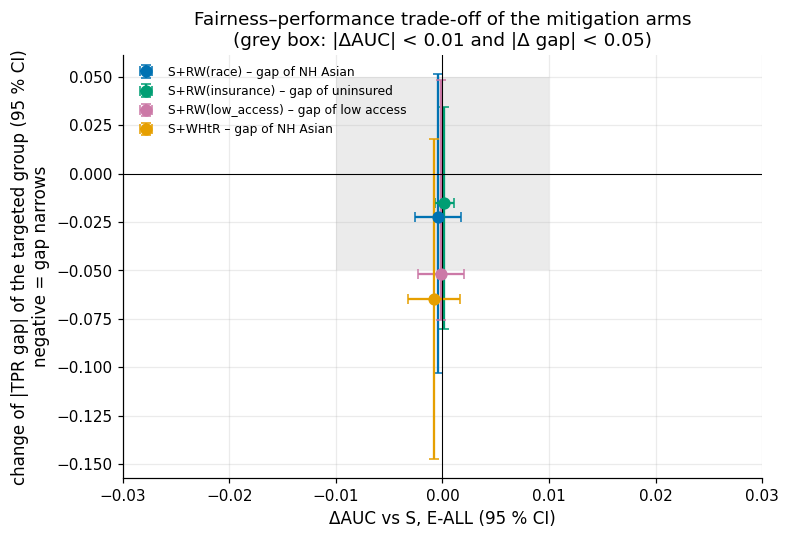

In [17]:
wh_auc = compare_auc(OOF[("S+WHtR", 1, "lr")], OOF[("S", 1, "lr")], "E-ALL", tag="whtr")
TO = []
for attr, tgt in RW_TARGET.items():
    a = RWT[(RWT["arm"] == f"S+RW({attr})") & (RWT["pop"] == "E-ALL")].iloc[0]
    e = RWE[(RWE["arm"] == f"S+RW({attr})") & (RWE["group"] == tgt)].iloc[0]
    TO.append({"arm": f"S+RW({attr})", "target": tgt, "d_auc": a["est"], "d_auc_lo": a["lo"], "d_auc_hi": a["hi"],
               "d_abs_eod": e["d_abs_eod"], "d_abs_eod_lo": e["d_abs_lo"], "d_abs_eod_hi": e["d_abs_hi"]})
TO.append({"arm": "S+WHtR", "target": "NH Asian", "d_auc": wh_auc["est"], "d_auc_lo": wh_auc["lo"], "d_auc_hi": wh_auc["hi"],
           "d_abs_eod": r_eod["est"], "d_abs_eod_lo": r_eod["lo"], "d_abs_eod_hi": r_eod["hi"]})
TO = pd.DataFrame(TO)
TO["in_no_change_box"] = (TO["d_auc_lo"] > -0.01) & (TO["d_auc_hi"] < 0.01) & (TO["d_abs_eod_lo"] > -GAP) & (TO["d_abs_eod_hi"] < GAP)
print(TO.round(4).to_string(index=False))
TO.to_csv(OUT / "tradeoff.csv", index=False)
S8["tradeoff"] = TO.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.add_patch(plt.Rectangle((-0.01, -GAP), 0.02, 2 * GAP, color=C.OKABE_ITO["grey"], alpha=0.15, lw=0))
cols = [C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["purple"], C.OKABE_ITO["orange"]]
for (_, r), col in zip(TO.iterrows(), cols):
    ax.errorbar(r["d_auc"], r["d_abs_eod"], xerr=[[r["d_auc"] - r["d_auc_lo"]], [r["d_auc_hi"] - r["d_auc"]]],
                yerr=[[r["d_abs_eod"] - r["d_abs_eod_lo"]], [r["d_abs_eod_hi"] - r["d_abs_eod"]]], fmt="o", color=col,
                capsize=3, ms=7, label=f"{r['arm']} – gap of {r['target']}")
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("ΔAUC vs S, E-ALL (95 % CI)")
ax.set_ylabel("change of |TPR gap| of the targeted group (95 % CI)\nnegative = gap narrows")
ax.set_xlim(-0.03, 0.03)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Fairness–performance trade-off of the mitigation arms\n(grey box: |ΔAUC| < 0.01 and |Δ gap| < 0.05)")
f85 = plots.savefig(fig, "S8_tradeoff", caption="F8-5. Fairness-performance plane for the mitigation arms (Tier 1): ΔAUC "
                    "against arm S on E-ALL (wider of corrected-t and paired-bootstrap CI) versus the change in the absolute "
                    "TPR gap of the targeted group at specificity 0.80 (paired stratified bootstrap); grey box = no practical change.")
plt.show()

**So what.** All four mitigations sit on the vertical line: none costs discrimination (every ΔAUC CI inside ±0.01).
All four point downwards – each narrows the gap it targets – but every gap interval still crosses zero, and the
intervals are wider than ±0.05, so no mitigation reaches the "no change" box either: the data cannot tell a small
improvement from none. The WHtR fix shows the largest point gain for its target. There is no trade-off to manage
because there is no demonstrated benefit to trade against; with the present sample sizes the honest summary is
"cheap, harmless, not shown to help".

## 12 Within-group calibration
**Why.** Equal sensitivity is one fairness criterion; calibration within groups (a predicted 20 % meaning 20 % in
every group) is another, and the two cannot in general hold together when prevalences differ (Chouldechova 2017).
Arm S is class-weighted, so its probabilities are inflated by design and only *relative* calibration across groups
can be read from it. Absolute calibration is therefore checked on **S−B6a** – arm S without class weights, equivalent
in AUC (§7) – which is the calibrated sibling of S. For each group: observed-to-expected ratio O:E (bootstrap CI),
calibration-in-the-large (CITL, log-odds offset; 0 = calibrated) and calibration slope (1 = calibrated). Here the
bootstrap resamples within groups but *not* within label, so the number of observed cases varies across replicates
(a label-stratified bootstrap would fix the numerator of O:E and understate its uncertainty).

S-B6a overall: O:E 1.018, CITL +0.028, slope 0.971
 attribute            group    n  n_pos  mean_pred  observed    oe  oe_lo  oe_hi   citl  slope  oe_S_relative  oe_ci_excludes_1
      race         NH White 2727    398      0.167     0.146 0.876  0.814  0.950 -0.203  1.033          0.857              True
      race         NH Black  540    131      0.185     0.243 1.311  1.131  1.488  0.463  0.780          1.310              True
      race         NH Asian  252     40      0.118     0.159 1.351  1.052  1.724  0.449  1.015          1.199              True
      race Mexican American  309     69      0.160     0.223 1.391  1.142  1.597  0.564  0.990          1.374              True
      race   Other Hispanic  465     82      0.165     0.176 1.068  0.903  1.224  0.106  1.103          1.054             False
      race      Other/Multi  291     57      0.182     0.196 1.077  0.835  1.330  0.127  0.906          1.112             False
 insurance          insured 4186    725      0.170   

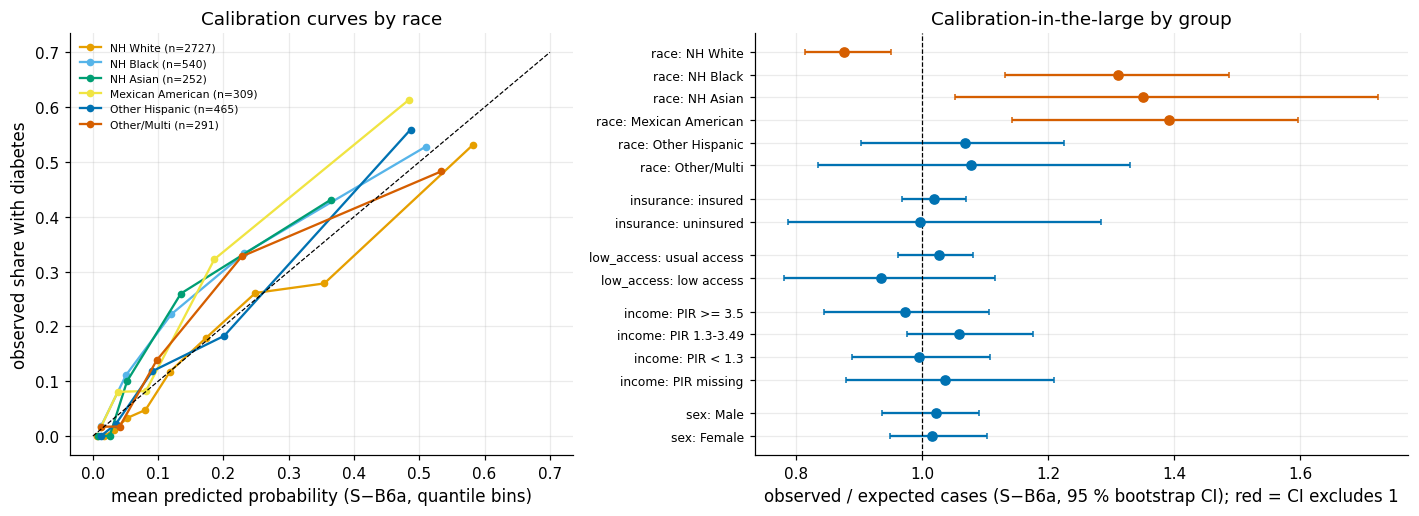

In [18]:
pC = PM[("S-B6a", 1, "lr")]
cal_rows = []
for attr in F.ATTRIBUTES:
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S-B6a", "S"), weights="group")
    lvls = F.LEVELS[attr]
    oe_all_S = y.sum() / pS.sum()
    for g_i, g_nm in enumerate(lvls):
        m = grp[attr].eq(g_nm).to_numpy()
        slope, icpt, citl = ek._calibration(y[m], pC[m])
        e, lo, hi, _ = F.summarise(point["oe"][0, 0, g_i], boot["oe"][:, 0, g_i])
        cal_rows.append({"attribute": attr, "group": g_nm, "n": int(m.sum()), "n_pos": int(y[m].sum()),
                         "mean_pred": pC[m].mean(), "observed": y[m].mean(), "oe": e, "oe_lo": lo, "oe_hi": hi,
                         "citl": citl, "slope": slope, "oe_S_relative": point["oe"][0, 1, g_i] / oe_all_S})
CAL = pd.DataFrame(cal_rows)
CAL["oe_ci_excludes_1"] = (CAL["oe_lo"] > 1) | (CAL["oe_hi"] < 1)
slope_all, _, citl_all = ek._calibration(y, pC)
print(f"S-B6a overall: O:E {y.sum() / pC.sum():.3f}, CITL {citl_all:+.3f}, slope {slope_all:.3f}")
print(CAL.round(3).to_string(index=False))
CAL.to_csv(OUT / "group_calibration.csv", index=False)
S8["calibration"] = dict(table=CAL.round(5).to_dict("records"), overall=dict(oe=float(y.sum() / pC.sum()), citl=citl_all, slope=slope_all),
                         groups_oe_ci_excl_1=CAL.loc[CAL["oe_ci_excludes_1"], ["attribute", "group", "oe"]].round(3).to_dict("records"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for g_nm, col in zip(F.LEVELS["race"], plots.PALETTE):
    m = grp["race"].eq(g_nm).to_numpy()
    nb = 5 if m.sum() < 600 else 10
    q = pd.qcut(pC[m], nb, labels=False, duplicates="drop")
    d_ = pd.DataFrame({"p": pC[m], "y": y[m], "q": q}).groupby("q").mean()
    ax.plot(d_["p"], d_["y"], "o-", color=col, label=f"{g_nm} (n={int(m.sum())})", ms=4)
ax.plot([0, 0.7], [0, 0.7], color="black", lw=0.8, ls="--")
ax.set_xlabel("mean predicted probability (S−B6a, quantile bins)"); ax.set_ylabel("observed share with diabetes")
ax.set_title("Calibration curves by race"); ax.legend(fontsize=7)
ax = axes[1]
k = 0; yt, yl = [], []
for attr in F.ATTRIBUTES:
    for _, r in CAL[CAL["attribute"] == attr].iterrows():
        ax.errorbar(r["oe"], -k, xerr=[[r["oe"] - r["oe_lo"]], [r["oe_hi"] - r["oe"]]], fmt="o",
                    color=C.OKABE_ITO["vermillion"] if r["oe_ci_excludes_1"] else C.OKABE_ITO["blue"], capsize=2)
        yt.append(-k); yl.append(f"{attr}: {r['group']}"); k += 1
    k += 0.5
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=8)
ax.set_xlabel("observed / expected cases (S−B6a, 95 % bootstrap CI); red = CI excludes 1")
ax.set_title("Calibration-in-the-large by group")
fig.tight_layout()
f84 = plots.savefig(fig, "S8_group_calibration", caption="F8-4. Within-group calibration of arm S-B6a (arm S without class "
                    "weights, AUC-equivalent): calibration curves by race (quantile bins) and observed/expected ratio by audit "
                    "group with stratified bootstrap 95 % CI (E-ALL, Tier 1, training part OOF).")
plt.show()

**So what.** The calibrated sibling is well calibrated overall (O:E about 1.02, slope about 0.97) and across insurance,
access, income and sex, but **not across race**: it under-predicts for NH Black, NH Asian and Mexican American adults
(about 30–40 % more cases than predicted, CIs excluding 1) and over-predicts for NH White adults. This is the price of a
race-blind model when prevalence differs by race at the same feature values: the score is an average over groups. It is
also the second face of the TPR gap for Asian adults – their scores are too low on both the ranking and the
probability scale. Correcting it would require race as an input or a race-specific recalibration, which the project
excludes for the same reasons as group thresholds (section 10); it is reported as a limitation, and any use of the
probabilities for individual counselling should carry this caveat.

## 14 Storage
**Why.** Every number of this section is stored in `results/metrics_S8.json` (via `results_io`) and the tables in
`results/S8/`, so that S10 and the slides read them instead of re-typing them.

In [19]:
for nm, df_ in {"group_metrics_eall_t1": GT1, "eod_eall_t1": ET1, "group_metrics_escreen_t1": GTs, "eod_escreen_t1": ETs,
                "group_metrics_eall_t2": GT2, "eod_eall_t2": ET2,
                "permutation": pd.concat([PERM1, PERMs, PERM2], ignore_index=True)}.items():
    df_.to_csv(OUT / f"{nm}.csv", index=False)
S8["runtime_seconds"] = time.time() - T_START
R.save_section("S8", S8)
print(f"saved results/metrics_S8.json and {len(list(OUT.glob('*.csv')))} tables in results/S8; runtime {S8['runtime_seconds']:.0f} s ({C.NB_MODE})")

saved results/metrics_S8.json and 18 tables in results/S8; runtime 79 s (FAST)
